# Bitácora — Dataset de comandos de voz y preprocesamiento

**Trabajo Final · Inteligencia Artificial I · Ingeniería en Mecatrónica · UNCUYO · 2026**  
**Corte documentado: 20/10/2026 · Primera versión: 150 muestras de cinco hablantes.**

El objetivo es preparar grabaciones comparables de **reconocer**, **identificar** y **salir** para la posterior extracción de características acústicas y clasificación con K-NN. Las clases son las palabras; los identificadores H001–H005 organizan las personas y permiten evitar que una misma voz aparezca en particiones diferentes.

La captura guiada y el preprocesamiento están implementados y fueron ejecutados localmente en Windows. La recolección continúa, con una meta inicial de al menos ocho personas, sin cupos máximos. H001/H002 se emplearon para desarrollar el procedimiento; la evaluación final requiere voces reservadas que no se usen para elegir parámetros.

Esta bitácora explica el método, consulta los catálogos disponibles y facilita revisar ejemplos. No graba, modifica metadatos, ajusta parámetros ni asigna particiones. El resumen fechado documenta el corte actual; las celdas de código muestran el dataset disponible al ejecutarlas, que puede ser mayor en el futuro. Un archivo procesado no queda automáticamente validado para entrenamiento.

**Guía de lectura:** distribución y controles; procedimiento de señal; duraciones; comparación original/procesado; reproducibilidad; resultados y pendientes. La descripción completa está en [preprocesamiento_audio.md](../documentos/preprocesamiento_audio.md).


In [1]:
from pathlib import Path
from collections import Counter
import csv
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config/audio_v1.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError("Abrir el notebook dentro de la raíz del proyecto o notebooks/.")
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))
from preprocesamiento_audio import leer_wav_pcm16

def leer_csv(ruta):
    if not ruta.exists():
        return []
    with ruta.open(encoding="utf-8-sig", newline="") as f:
        return list(csv.DictReader(f))

capturas = leer_csv(RAIZ / "datos/audio/metadatos.csv")
actual = RAIZ / "datos/audio/procesados/actual.json"
procesados = []
referencia = None
if actual.exists():
    referencia = json.loads(actual.read_text(encoding="utf-8"))
    procesados = leer_csv(RAIZ / referencia["ruta_catalogo"])
print("Capturas:", len(capturas))
print("Versión activa:", referencia["version"] if referencia else "aún no se ejecutó el preprocesamiento")
print("Resultados en el catálogo activo:", len(procesados))
ids_procesados = {r["muestra_id"] for r in procesados}
pendientes = [r["muestra_id"] for r in capturas if r["muestra_id"] not in ids_procesados]
if pendientes:
    print("Capturas nuevas sin resultado en esta versión:", len(pendientes))

Capturas: 150
Versión activa: audio_preprocesamiento_v1_3f3a7a105289
Resultados en el catálogo activo: 150


## 1. Composición del dataset y controles de calidad

En el corte documentado, cada persona aportó diez tomas de cada palabra: 30 por hablante y 50 por clase. Este equilibrio de cantidades no garantiza diversidad suficiente ni precisión de reconocimiento.

Todas las sesiones de una persona deberán permanecer en la misma partición de la evaluación principal. Las 150 muestras siguen sin asignar; este notebook no decide entrenamiento, validación o prueba.

Los avisos de captura describen el original y los de preprocesamiento corresponden a controles de la etapa siguiente. Una decisión humana puede conservar una muestra con aviso sin borrar ese aviso. Se revisarán especialmente los recortes con advertencias y ejemplos de los tres comandos de cada persona.


In [2]:
comandos = ("reconocer", "identificar", "salir")
conteos = Counter((r["hablante"], r["comando"]) for r in capturas)
print(f"{'Hablante':<12} {'Reconocer':>10} {'Identificar':>12} {'Salir':>8}")
for h in sorted({r["hablante"] for r in capturas}):
    print(f"{h:<12} {conteos[h, 'reconocer']:>10} {conteos[h, 'identificar']:>12} {conteos[h, 'salir']:>8}")
print("Estados activos:", dict(Counter(r["estado_procesamiento"] for r in procesados)))
print("Particiones de captura:", dict(Counter(r["particion"] for r in capturas)))
print("\nMuestras con avisos:")
for r in procesados:
    if r["avisos_calidad"] or r["avisos_preprocesamiento"]:
        print(r["muestra_id"])
        print("  Captura:", r["avisos_calidad"] or "ninguno")
        print("  Procesamiento:", r["avisos_preprocesamiento"] or "ninguno")
        print("  Revisión:", r["decision_revision"], r["motivo_revision"])

Hablante      Reconocer  Identificar    Salir
H001                 10           10       10
H002                 10           10       10
H003                 10           10       10
H004                 10           10       10
H005                 10           10       10
Estados activos: {'procesado': 127, 'procesado_con_avisos': 23}
Particiones de captura: {'sin_asignar': 150}

Muestras con avisos:
H001_S001_identificar_0001
  Captura: picos_cercanos_al_limite
  Procesamiento: picos_cercanos_al_limite_original
  Revisión: pendiente 
H001_S001_salir_0010
  Captura: picos_cercanos_al_limite
  Procesamiento: picos_cercanos_al_limite_original
  Revisión: pendiente 
H002_S001_reconocer_0001
  Captura: picos_cercanos_al_limite
  Procesamiento: picos_cercanos_al_limite_original
  Revisión: pendiente 
H002_S001_reconocer_0009
  Captura: picos_cercanos_al_limite
  Procesamiento: picos_cercanos_al_limite_original
  Revisión: pendiente 
H002_S001_reconocer_0010
  Captura: picos_cercanos_al_l

## 2. Procedimiento aplicado

Cada original se convierte a flotante y, si tiene varios canales, a mono. Se resta su media cuando está habilitado y se remuestrea con filtrado antialias a **16 kHz**.

Se mide RMS en ventanas de 20 ms cada 10 ms. Dos umbrales de energía, configurables y relativos a un piso estimado, localizan actividad aproximada. Se conserva desde la primera hasta la última isla retenida, con **150 ms de margen** en ambos extremos. No se recortan los silencios internos ni se estira la palabra.

La ganancia sobre el recorte es:

$$g=\min\left(\frac{0.8}{\max|x|},\;10^{6/20}\right).$$

Se busca un pico de 0.8 sin amplificar más de 6 dB. Un aviso de amplificación limitada significa que se respetó ese límite. Una captura sin suficiente actividad no se amplifica y conserva su original.

Los parámetros no garantizan detección de voz: ruidos variables pueden activar el detector y sonidos débiles pueden quedar fuera. La comparación por escucha permite verificar consonantes y márgenes.

## 3. Duraciones resultantes

Se espera que las duraciones sean diferentes entre tomas y palabras. Los puntos muestran resultados individuales, no rendimiento de clasificación. Todavía no se eligió la representación de tamaño fijo para K-NN.

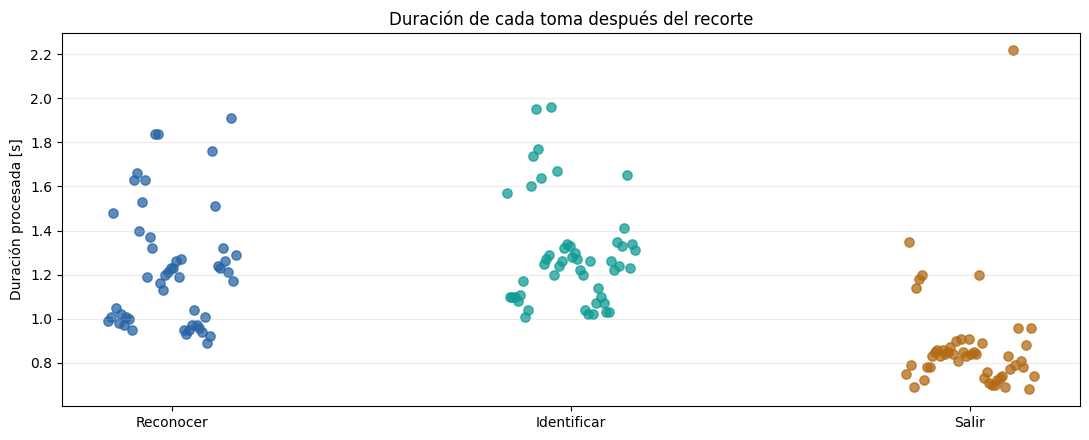

In [3]:
con_salida = [r for r in procesados if r["ruta_procesada"]]
if con_salida:
    fig, ax = plt.subplots(figsize=(11, 4.5))
    colores = ["#2764a5", "#119c94", "#b26a14"]
    for i, comando in enumerate(comandos):
        duraciones = [float(r["duracion_procesada_s"]) for r in con_salida if r["comando"] == comando]
        if duraciones:
            posiciones = i + np.linspace(-.16, .16, len(duraciones))
            ax.scatter(posiciones, duraciones, color=colores[i], alpha=.75, s=45)
    ax.set_xticks(range(3), [c.capitalize() for c in comandos])
    ax.set(ylabel="Duración procesada [s]", title="Duración de cada toma después del recorte")
    ax.grid(axis="y", alpha=.25)
    plt.tight_layout()
    plt.show()
else:
    print("No hay WAV procesados para graficar.")

## 4. Comparación de una muestra

Cambiar `MUESTRA_ID` por el identificador que se quiera revisar; `None` selecciona la primera captura. Para revisar el caso confirmado por el autor, usar `H002_S001_identificar_0009`.

Los reproductores usan `normalize=False`, para que el navegador no iguale las amplitudes por su cuenta. El gráfico alinea el procesado con el intervalo del original del que proviene. El volumen de reproducción del equipo también influye en la escucha.
La opción `REPRODUCIR_AUDIO=False` permite ejecutar las visualizaciones sin incrustar voces. Cambiarla a `True` para escuchar localmente y borrar todas las salidas antes de publicar el notebook. Los gráficos no reemplazan la escucha.


Muestra: H001_S001_reconocer_0001
ORIGINAL: 48000 Hz — 3.0 s
Estado: procesado
Avisos: ninguno
Decisión humana: pendiente 
PROCESADO: 16000 Hz — 0.99 s — ganancia: -0.22 dB


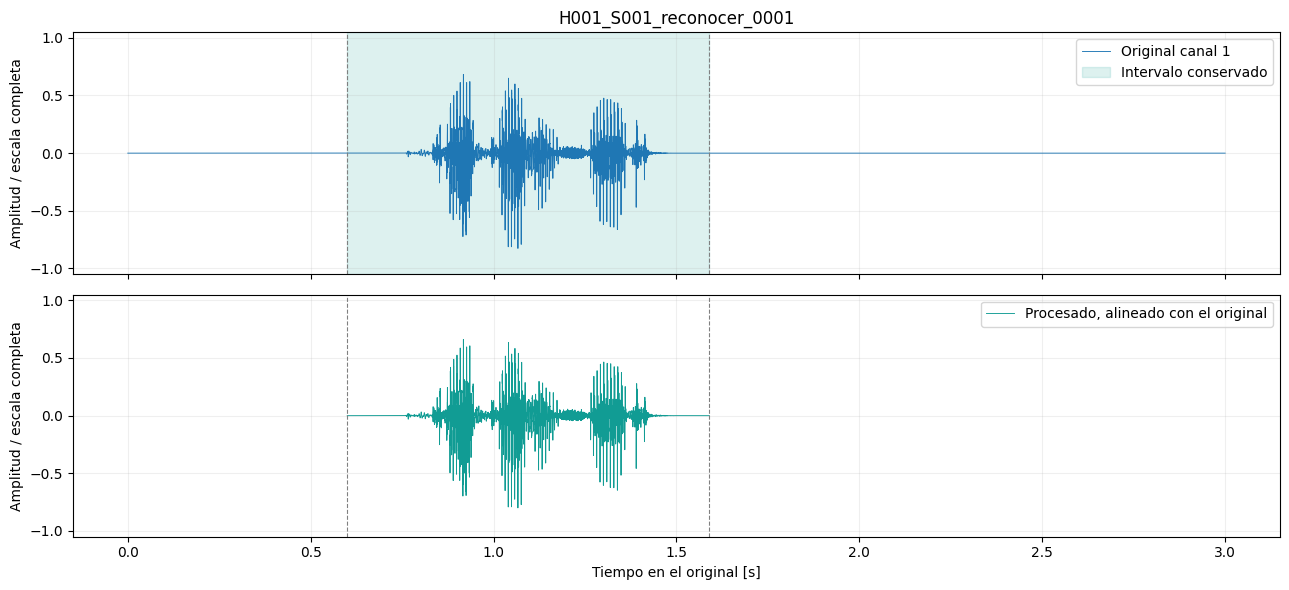

In [4]:
REPRODUCIR_AUDIO = False  # Activar solo para escuchar localmente.
MUESTRA_ID = None
muestra = next((r for r in capturas if r["muestra_id"] == MUESTRA_ID), None) if MUESTRA_ID else (capturas[0] if capturas else None)
if MUESTRA_ID and muestra is None:
    raise ValueError("Ese identificador no aparece en el catálogo de captura.")
if muestra:
    original, fs = leer_wav_pcm16(RAIZ / muestra["ruta_original"])
    x = original.astype(float) / 32768
    r = next((r for r in procesados if r["muestra_id"] == muestra["muestra_id"]), None)
    print("Muestra:", muestra["muestra_id"])
    print("ORIGINAL:", fs, "Hz —", len(x)/fs, "s")
    if REPRODUCIR_AUDIO:
        display(Audio(x[:, 0] if x.shape[1] == 1 else x.T, rate=fs, normalize=False))
    if r:
        print("Estado:", r["estado_procesamiento"])
        print("Avisos:", r["avisos_preprocesamiento"] or "ninguno")
        print("Decisión humana:", r["decision_revision"], r["motivo_revision"])
    if r and r["ruta_procesada"]:
        procesado, fs_p = leer_wav_pcm16(RAIZ / r["ruta_procesada"])
        y = procesado[:, 0].astype(float)/32768
        inicio, fin = float(r["recorte_inicio_s"]), float(r["recorte_fin_s"])
        print("PROCESADO:", fs_p, "Hz —", len(y)/fs_p, "s — ganancia:", round(float(r["ganancia_db"]), 2), "dB")
        if REPRODUCIR_AUDIO:
            display(Audio(y, rate=fs_p, normalize=False))
        fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, sharey=True)
        for canal in range(x.shape[1]):
            axes[0].plot(np.arange(len(x))/fs, x[:, canal], lw=.65, label=f"Original canal {canal+1}")
        axes[0].axvspan(inicio, fin, alpha=.14, color="#119c94", label="Intervalo conservado")
        axes[1].plot(inicio+np.arange(len(y))/fs_p, y, lw=.65, color="#119c94", label="Procesado, alineado con el original")
        for ax in axes:
            ax.axvline(inicio, color="gray", linestyle="--", lw=.8)
            ax.axvline(fin, color="gray", linestyle="--", lw=.8)
            ax.set_ylim(-1.05, 1.05)
            ax.set_ylabel("Amplitud / escala completa")
            ax.grid(alpha=.2)
            ax.legend(loc="upper right")
        axes[0].set_title(muestra["muestra_id"])
        axes[1].set_xlabel("Tiempo en el original [s]")
        plt.tight_layout()
        plt.show()
    else:
        print("Esta captura aún no tiene WAV procesado. Revisar el estado y el JSON de detalle si existe.")

## 5. Integridad y reproducibilidad

Los resultados se versionan por configuración, código y versiones de NumPy/SciPy. Repetir el lote con la misma versión verifica y omite resultados ya confirmados. Un cambio de método produce otra carpeta, conservando las anteriores. `actual.json` señala la versión activa.

Las columnas originales de `metadatos.csv` mantienen su significado; `ruta_procesada` y `estado_procesamiento` apuntan al resultado activo. Los detalles nuevos están en el catálogo de la versión y en un JSON por muestra. La asignación de particiones sigue siendo un paso independiente.

In [5]:
if referencia:
    carpeta = (RAIZ / referencia["ruta_catalogo"]).parent
    procedimiento = json.loads((carpeta / "procedimiento.json").read_text(encoding="utf-8"))
    resumen = json.loads((carpeta / "resumen.json").read_text(encoding="utf-8"))
    print("Versión:", resumen["version"])
    print("Firma:", resumen["firma_procedimiento"])
    print("NumPy / SciPy:", procedimiento["numpy"], procedimiento["scipy"])
    print("Última ejecución: nuevos", resumen["nuevos"], "/ omitidos", resumen["omitidos"])
    print("Configuración:")
    print(json.dumps(procedimiento["configuracion"], indent=2, ensure_ascii=False))

Versión: audio_preprocesamiento_v1_3f3a7a105289
Firma: 3f3a7a105289b16f394a538823ad71b973a35e8c578c5990ebeb41b2b9a7a19b
NumPy / SciPy: 2.3.5 1.17.0
Última ejecución: nuevos 0 / omitidos 150
Configuración:
{
  "version": "audio_preprocesamiento_v1",
  "frecuencia_hz": 16000,
  "quitar_media": true,
  "ventana_ms": 20,
  "salto_ms": 10,
  "percentil_ruido": 20,
  "umbral_fuerte_min_dbfs": -42,
  "umbral_debil_min_dbfs": -48,
  "contraste_fuerte_db": 12,
  "contraste_debil_db": 6,
  "hueco_max_ms": 120,
  "isla_min_ms": 60,
  "actividad_min_ms": 120,
  "margen_ms": 150,
  "borde_aviso_ms": 50,
  "pico_objetivo": 0.8,
  "ganancia_max_db": 6,
  "pico_saturacion": 0.999,
  "fraccion_saturada_aviso": 0.001
}


## 6. Resultados del corte — 20/10/2026

La primera versión documentada reúne **150 tomas de cinco hablantes (H001–H005)**:
10 por comando y persona, 30 por persona y 50 por clase. La recolección permanece
abierta; la meta inicial es incorporar al menos ocho personas, sin establecer un
máximo ni suponer que esa cantidad garantiza precisión de reconocimiento.

| Hablante | Reconocer | Identificar | Salir | Total | Con avisos en captura |
|---|---:|---:|---:|---:|---:|
| H001 | 10 | 10 | 10 | 30 | 2 |
| H002 | 10 | 10 | 10 | 30 | 4 |
| H003 | 10 | 10 | 10 | 30 | 4 |
| H004 | 10 | 10 | 10 | 30 | 3 |
| H005 | 10 | 10 | 10 | 30 | 2 |
| **Total** | **50** | **50** | **50** | **150** | **15** |

El CSV entregado contiene 150 identificadores únicos y 150 hashes originales
distintos. Las 150 filas tienen ruta procesada y permanecen `sin_asignar`.
La ejecución local en Windows informó **150 originales y metadatos coherentes**.
Esta evidencia proviene del catálogo y de la salida de terminal aportada por el
autor; la revisión documental no volvió a calcular hashes sobre los WAV.

El procedimiento activo es `audio_preprocesamiento_v1_3f3a7a105289`:

| Resultado de la ejecución local | Cantidad |
|---|---:|
| Procesados sin avisos | 127 |
| Procesados con avisos | 23 |
| Nuevos en la repetición del lote | 0 |
| Resultados existentes verificados y omitidos | 150 |

La terminal registró 15 avisos `picos_cercanos_al_limite_original`, 6
`amplificacion_limitada` y 2 `actividad_cerca_del_final`. Los avisos de captura
(15 tomas) y los de procesamiento (23 tomas) corresponden a controles diferentes;
no se suman como si fueran muestras distintas. Los tipos de aviso pueden
coexistir en una misma toma en futuras ejecuciones.

Estos conteos verifican el avance de captura y procesamiento; no son tasas de
acierto ni certifican que las 150 tomas sean aptas para entrenar. La configuración
de revisión recibida registra explícitamente la conservación de
`H002_S001_identificar_0009`, cuya palabra fue confirmada completa por escucha.
Conservar otras tomas al grabarlas no equivale a registrar la revisión de su
recorte procesado. No se declara terminada la revisión auditiva individual de
los 23 resultados con avisos.

### Alcance de las verificaciones

- **Antecedente de desarrollo (17/10/2026):** se registraron 27 pruebas automáticas aprobadas en Linux y una prueba de procesamiento sobre las primeras 60 grabaciones. Es un antecedente, no una ejecución nueva sobre las 150 muestras.
- **Evidencia local actual:** catálogo de 150 filas y salidas de terminal en Windows aportadas por el autor. La repetición del lote verifica y omite los resultados existentes; el grabador informa integridad coherente.
- **Revisión documental de este corte:** conteos, estados, identificadores únicos y particiones contrastados con el CSV. No se recibieron los 150 WAV para repetir su análisis ni se certificó su calidad por escucha.

### Límites y transición a la siguiente etapa

La captura y el preprocesamiento v1 quedan documentados y disponibles para iniciar la **extracción de características y vectorización**. No se implementaron todavía MFCC, representación de tamaño fijo ni K-NN. El recorte mantiene duraciones diferentes y no altera la velocidad de las palabras.

Antes de entrenar y evaluar se deberá completar el registro de decisiones de calidad y fijar una asignación reproducible por hablante. H001/H002 pertenecen al desarrollo; cualquier otra voz usada para elegir características o parámetros también deja de ser una prueba final independiente. Las personas reservadas para prueba no se usarán para ajustar el método. Una demostración con voces conocidas se documentará como tal y no como evaluación de generalización.

La recolección continúa. Al incorporar nuevas personas se ejecutará el mismo lote incremental, se revisarán sus avisos y se actualizará el corte documental cuando corresponda. No hace falta modificar el código del notebook por cada participante.

Los controles no resuelven el rechazo de palabras desconocidas, ruido o silencio del sistema final. No se incorpora una cuarta clase ni escucha continua en esta etapa. La documentación registra el uso de IA generativa y distingue pruebas automáticas de decisiones humanas.
